# Progression models from a cohort's DNA with MHN

We grow a cohort of small tumors under a planted network of three events, read which events each tumor carries, as a cross-sectional study of the tumors' DNA would, and fit a Mutual Hazard Network (MHN, [Schill et al. 2020](https://github.com/spang-lab/LearnMHN)) to the patients-by-events matrix.
We then compare MHN's estimate with the planted network.
[The cohort tutorial](04_cohort.ipynb) shows how a cohort is grown and what its answer key holds.

MHN models events that change each other's rates of acquisition, so that an event that promotes another makes it arise sooner.
The network that `iscc` plants acts on fitness instead.
Every event arises at the mutation rate whatever the others, and the events change the division rate of the clone that carries them, as selection does in real tumors.
MHN is therefore asked to recover a network of a kind it does not model, as it is in a real cohort.
MHN runs in its own conda environment, `iscc-mhn`, from a short script that the notebook writes.

In [1]:
import os
import tempfile

import numpy as np
import pandas as pd
import yaml
from IPython.display import Image

from iscc.cohort import Cohort
from iscc.integrations import DETECTION_LIMIT, cooccurrence_scores, event_cell_fractions, patient_event_vector
from iscc.tumor import GenotypeTumor

CONFIG = os.path.abspath("tutorial_config.yaml")
MHN_PYTHON = os.path.expanduser("~/miniconda3/envs/iscc-mhn/bin/python")
os.chdir(tempfile.mkdtemp())        # the data and the tool's outputs go to a scratch directory

## The planted network

An event is a module of driver genes, acquired when a mutation hits any gene of the module.
We plant three events of four genes each through `epistasis_params` in the selection parameters of the configuration.
Each event raises the log fitness of the clones that carry it by 0.1, and carrying E1 and E2 together raises it by another 0.4.
E0 interacts with no other event, so its pairs are the reference within the cohort for a pair without interaction.

In [2]:
config = yaml.safe_load(open(CONFIG))
config["selection_params"]["epistasis_params"] = {
    "n_events": 3, "event_size": 4,
    "planted": {"effects": 0.1, "interactions": [(1, 2, 0.4)]},
}
with open("config.yaml", "w") as f:
    yaml.safe_dump(config, f)

## A cohort of 300 small tumors

[`Cohort`](../reference/Cohort.md) grows every patient from its own evolution seed over one gene layout, so all patients share the network.
Our growth function grows a [`GenotypeTumor`](../reference/GenotypeTumor.md) from the configuration to 3,000 cancer cells.
We grow the patients one at a time with `grow_patient` and keep only the events of each, so that the memory stays that of one tumor.
An event counts as present in a patient when at least 5% of the cancer cells carry it (`DETECTION_LIMIT`), the detection limit of bulk sequencing.
We also keep the share of cancer cells that carry each event, to see how clonal the detected events are.

In [3]:
def grow(seed, layout_seed):
    tumor = GenotypeTumor(config="config.yaml", seed=seed, layout_seed=layout_seed)
    tumor.grow(n_steps=3000, target_cancer=3000, materialize=False)
    return tumor


cohort = Cohort(grow, patient_seeds=range(1, 301))
rows, fractions = [], []
for i in range(cohort.n_patients):
    tumor = cohort.grow_patient(i)
    rows.append(patient_event_vector(tumor, min_freq=DETECTION_LIMIT))
    fractions.append(event_cell_fractions(tumor))
names = tumor.selection.epistasis.event_names()
events = pd.DataFrame(rows, columns=names, index=[f"P{i}" for i in range(cohort.n_patients)])
fractions = pd.DataFrame(fractions, columns=names, index=events.index)
events.to_csv("events.csv")
print("share of patients with each event:", events.mean().round(2).to_dict())
print("share of the detected events carried by at least 95% of the cancer cells:",
      round(float((fractions[events == 1] >= 0.95).sum().sum() / events.sum().sum()), 2))

share of patients with each event: {'E0': 0.21, 'E1': 0.24, 'E2': 0.25}
share of the detected events carried by at least 95% of the cancer cells: 0.87


The answer key holds the planted network, which every patient shares, as the matrix of pairwise interactions.

In [4]:
truth = tumor.epistasis_ground_truth()
pd.DataFrame(truth["E"], index=names, columns=names)

,E0,E1,E2
E0,0.0,0.0,0.0
E1,0.0,0.0,0.4
E2,0.0,0.4,0.0


Before fitting MHN, we look at how often the events co-occur.
The package's baseline, `cooccurrence_scores`, gives the log odds ratio of each pair, positive when two events are found together more often than by chance.

In [5]:
print(pd.crosstab(events["E1"], events["E2"]), "\n")
pd.DataFrame(cooccurrence_scores(events.to_numpy()), index=names, columns=names).round(2)

E2    0   1
E1         
0   186  43
1    40  31 



,E0,E1,E2
E0,0.00,0.41,0.14
E1,0.41,0.00,1.20
E2,0.14,1.20,0.00


## MHN

The script below fits the classical MHN as the package's demo does, with the symmetric sparse penalty and its strength chosen by five-fold cross-validation and the one-standard-error rule.
It also fits MHN at the package's default penalty strength (1/n for n patients), since cross-validation can shrink every interaction to zero, and draws the package's own figure of that model.
In MHN's matrix Θ, the off-diagonal entry Θ[i, j] is the log factor by which event j changes the rate of event i, and the diagonal holds the base rates.

In [6]:
%%writefile run_mhn.py
import matplotlib.pyplot as plt
import mhn
import numpy as np
import pandas as pd
from mhn.optimizers import cMHNOptimizer

events = pd.read_csv("events.csv", index_col=0)
np.random.seed(0)                                       # the cross-validation folds
optimizer = cMHNOptimizer()
optimizer.load_data_matrix(events)
optimizer.set_penalty(cMHNOptimizer.Penalty.SYM_SPARSE)
lam = optimizer.lambda_from_cv(nfolds=5, steps=9)
for name, strength in [("cv", lam), ("default", 1 / len(events))]:
    model = optimizer.train(lam=strength, round_result=False)
    pd.DataFrame(model.log_theta, index=events.columns, columns=events.columns).to_csv(f"theta_{name}.csv")
    print(f"mhn {mhn.__version__}: {name} penalty strength {strength:.4f}")
model.plot()
plt.gcf().set_size_inches(8, 3.5)          # at three events the default size crowds the color bars
plt.savefig("mhn_theta.png", dpi=100, bbox_inches="tight")

Writing run_mhn.py


In [7]:
!MPLBACKEND=Agg PYTHONWARNINGS=ignore {MHN_PYTHON} run_mhn.py 2> mhn.log
theta = {name: pd.read_csv(f"theta_{name}.csv", index_col=0) for name in ["cv", "default"]}
theta["cv"].round(3)

mhn 1.2.3: cv penalty strength 0.0333
mhn 1.2.3: default penalty strength 0.0033


,E0,E1,E2
E0,-1.330,-0.003,-0.015
E1,-0.002,-1.177,0.002
E2,-0.014,0.002,-1.127


In [8]:
theta["default"].round(3)

,E0,E1,E2
E0,-1.137,-0.326,-0.614
E1,-0.309,-1.158,0.189
E2,-0.578,0.183,-1.058


The package's figure of the model at the default penalty strength shows the base rates and the off-diagonal Θ, with red for promoting and blue for inhibiting effects.

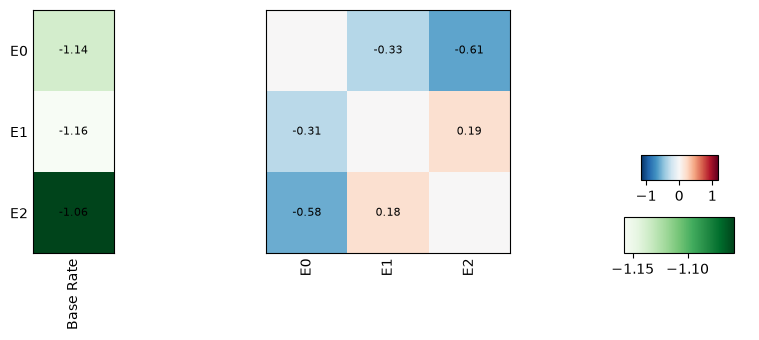

In [9]:
Image("mhn_theta.png")

## The co-occurrence baseline recovers the planted pair, and MHN does not

For each pair of events we compare the planted interaction with the co-occurrence log odds and with MHN's estimate, taking for MHN the larger in magnitude of Θ[i, j] and Θ[j, i].
A planted pair is recovered when its estimate has the planted sign and is larger in magnitude than every pair of the control event E0.

In [10]:
cooc = cooccurrence_scores(events.to_numpy())
rows = []
for i, j in [(0, 1), (0, 2), (1, 2)]:
    row = {"pair": f"{names[i]}-{names[j]}", "planted": truth["E"][i, j], "co-occurrence": cooc[i, j]}
    for name, t in theta.items():
        a, b = t.iat[i, j], t.iat[j, i]
        row[f"MHN ({name})"] = a if abs(a) >= abs(b) else b
    rows.append(row)
scores = pd.DataFrame(rows).set_index("pair").round(3)
control = scores.loc[["E0-E1", "E0-E2"]].abs().max()
recovered = (scores.loc["E1-E2"] > 0) & (scores.loc["E1-E2"].abs() > control)
print("E1-E2 recovered:", recovered.drop("planted").to_dict())
scores

E1-E2 recovered: {'co-occurrence': True, 'MHN (cv)': False, 'MHN (default)': False}


,planted,co-occurrence,MHN (cv),MHN (default)
pair,,,,
E0-E1,0.0,0.410,-0.003,-0.326
E0-E2,0.0,0.140,-0.015,-0.614
E1-E2,0.4,1.204,0.002,0.189


Each event was present in about a quarter of the patients, and E1 and E2 were found together in 31 of the 300 patients, more often than their frequencies predict.
The co-occurrence log odds ranked the planted pair E1–E2 first (1.20, against 0.41 and 0.14 for the pairs of the control event E0), so the planted synergy is visible in the cross-sectional data.
With the penalty strength chosen by cross-validation, MHN shrank every interaction to about zero, and the chosen strength was the largest of the package's default grid.
At the default strength, MHN gave E1–E2 a positive interaction (0.19), but it gave the two pairs of E0, which carry no interaction, larger negative ones (−0.33 and −0.61), so MHN recovered the planted pair in neither fit.

In principle, we expect a mismatch of this kind from the difference described at the top.
MHN assumes that events accumulate over an observation time that differs between patients, under which even independent events co-occur more often than chance.
In this cohort every tumor was observed at the same size, and 87% of the detected events were carried by at least 95% of the cancer cells, so most events were most likely acquired early, while the tumor was confined to its founding duct.
MHN may therefore read the weak co-occurrence of the E0 pairs as inhibition, while the planted synergy, which acts on the division rate and not on the order in which events are acquired, shows in the data only as co-occurrence.

## Making the benchmark harder or easier

More patients (`patient_seeds`) give MHN more power, and the module size (`event_size`) sets how often each event is found.
An event found in almost every patient, or in almost none, carries little information.
Larger effects and interactions in `planted` make the network easier to see, within the headroom of the division rate, which the configuration caps at `max_birth_rate`.
Order constraints with `dependency_params={"gating_mode": "accessibility"}`, under which an event can not arise before its parent, follow MHN's own assumption and make the benchmark easier, while the default fitness gating does not.
A different target size per patient, passed through `patient_kwargs` of [`Cohort`](../reference/Cohort.md), mixes early and late tumors as a real cohort does, and a higher detection limit (`min_freq`) keeps only the events that are clonal enough to be called.
Reading the events from simulated bulk DNA ([`bulkDNA`](../reference/bulkDNA.md)) instead of the true cell fractions adds the errors of variant calling, and [Shape the data](03_shape_the_data.ipynb) shows the DNA assays.